# [Learning rate scheduler](https://dacon.io/codeshare/2373)
학습률(Learning Rate)은 모델을 학습하기 위해서 필수적인 요소다. 학습률을 너무 크게 설정한다면, 최솟값에 도달하는 것이 어려우며, 너무 작게 설정하면, local minimum에 빠지거나 학습에 진전이 없을 수 있다. 이번 글에서는 학습률에 Schedular를 설정해서 학습률을 감쇠(Decay)하는 패키지를 다루어볼 것이다.

In [ ]:
import torch
import matplotlib.pyplot as plt

## Learning rate scheduler 종류

### LAMBDA LR
Epoch에 따른 가중치로 lr 를 점점 감소 시키는 Scheduler 입니다.
- LambdaLR은 가장 유연한 learning rate scheduler입니다. 어떻게 scheduling을 할 지 lambda 함수 또는 함수를 이용하여 정하기 때문입니다.
- LmabdaLR을 사용할 때 필요한 파라미터는 optimizer, lr_lambda입니다.

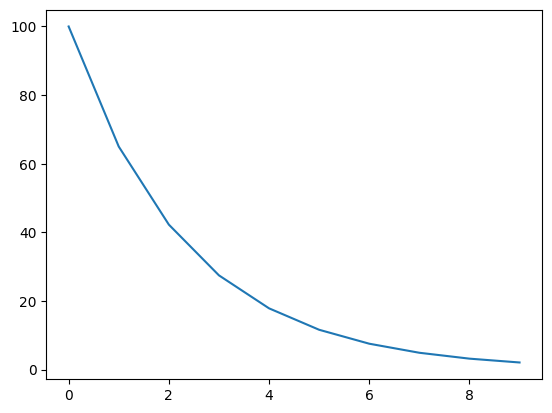

In [ ]:
# 모델 정의
model = torch.nn.Linear(2, 1)
# 모델이 학습할때 사용할 옵티마이저
# -> 옵티마이저별 learning rate에 대한 전략이 있음.
optimizer = torch.optim.SGD(model.parameters(), lr=100)
# 람다함수를 통해서 learning rate에 대한 전략 적용
lambda1 = lambda epoch: 0.65 ** epoch
# LambdaLR(옵티마이저, 직접작성한 람다함수)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda1)

lrs = []

for i in range(10):
    optimizer.step()
    lrs.append(optimizer.param_groups[0]["lr"])
    scheduler.step()

plt.plot(range(10),lrs)

### StepLR
특정 Step에 따라 lr 를 감소시키는 Scheduler 입니다.
- StepLR도 가장 흔히 사용되는 learning rate scheduler 중 하나입니다. 일정한 Step 마다 learning rate에 gamma를 곱해주는 방식입니다.
- StepLR에서 필요한 파라미터는 optimizer, step_size, gamma 입니다.

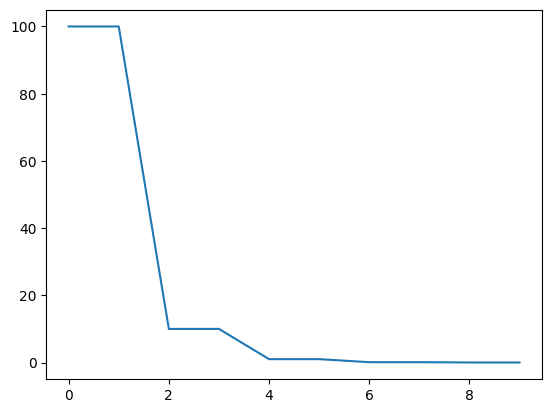

In [ ]:
model = torch.nn.Linear(2, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=100)

scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.1)
lrs = []

for i in range(10):
    optimizer.step()
    lrs.append(optimizer.param_groups[0]["lr"])
#     print("Factor = ",0.1 if i!=0 and i%2!=0 else 1," , Learning Rate = ",optimizer.param_groups[0]["lr"])
    scheduler.step()

plt.plot(range(10),lrs)

### MultiStepLR
특정 Step에 따른 감소가 아닌 사용자가 지정한 milestones 에 따라 lr 를 감소시키는 Scheduler 입니다.
- StepLR이 균일한 step size를 사용한다면 이번에 소개할 MultiStepLR은 step size를 여러 기준으로 적용할 수 있는 StepLR의 확장 버전입니다.
- StepLR과 사용방법은 비슷하며 StepLR에서 사용한 step_size 대신, milestones에 리스트 형태로 step 기준을 받습니다. 다음 예제를 살펴보겠습니다.

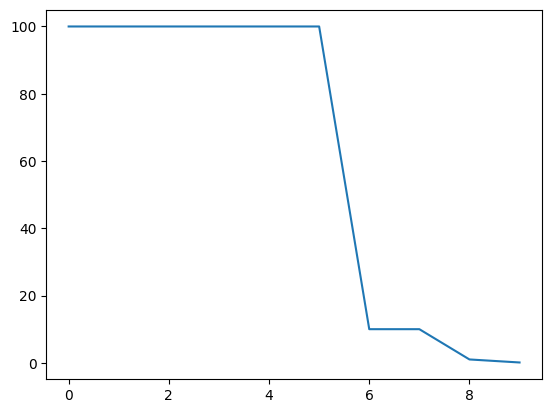

In [ ]:
model = torch.nn.Linear(2, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=100)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[6,8,9], gamma=0.1)
lrs = []

for i in range(10):
    optimizer.step()
    lrs.append(optimizer.param_groups[0]["lr"])
#     print("Factor = ",0.1 if i in [6,8,9] else 1," , Learning Rate = ",optimizer.param_groups[0]["lr"])
    scheduler.step()

plt.plot(range(10),lrs)

### ExponentialLR
- 지수적으로 learning rate가 감소하는 방법도 많이 사용합니다. 이번에 다룰 내용은 지수적으로 learning rate가 감소하는 ExponentialLR입니다.
- 지수적으로 감소하기 때문에 하이퍼 파라미터는 감소율 gamma 하나 입니다.

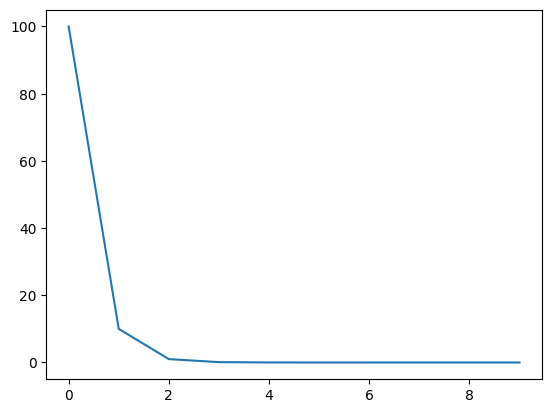

In [ ]:
model = torch.nn.Linear(2, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=100)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.1)
lrs = []


for i in range(10):
    optimizer.step()
    lrs.append(optimizer.param_groups[0]["lr"])
#     print("Factor = ",0.1," , Learning Rate = ",optimizer.param_groups[0]["lr"])
    scheduler.step()

plt.plot(lrs)

### CosineAnnealingLR
Cosine 파형을 사용하는 Scheduler 입니다.
- CosineAnnealingLR은 cosine 그래프를 그리면서 learning rate가 진동하는 방식입니다. 최근에는 learning rate가 단순히 감소하기 보다는 진동하면서 최적점을 찾아가는 방식을 많이 사용하고 있습니다. 이러한 방법 중 가장 간단하면서도 많이 사용되는 방법이 CosineAnnealingLR 방식입니다.
- CosineAnnealingLR에 사용되는 파라미터는 T_max 라는 반주기의 단계 크기값과 eta_min 이라는 최소값입니다.

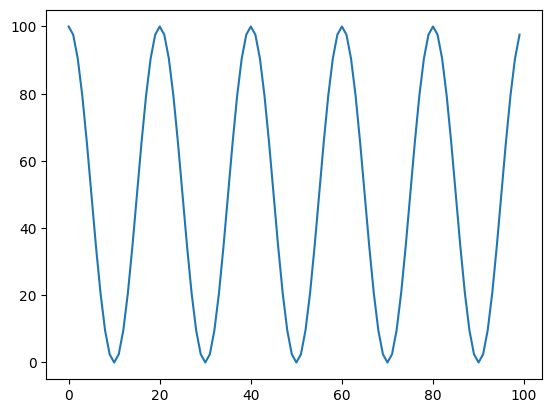

In [ ]:
model = torch.nn.Linear(2, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=100)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10, eta_min=0)
lrs = []


for i in range(100):
    optimizer.step()
    lrs.append(optimizer.param_groups[0]["lr"])
#     print("Factor = ",i," , Learning Rate = ",optimizer.param_groups[0]["lr"])
    scheduler.step()

plt.plot(lrs)

### CyclicLR
- CyclicLR 방법 또한 많이 사용하는 방법입니다. 앞에서 설명한 CosineAnnealingLR은 단순한 cosine 곡선인 반면에 CyclicLR은 3가지 모드를 지원하면서 변화된 형태로 주기적인 learning rate 증감을 지원합니다.
- 이 때 사용하는 파라미터로 base_lr, max_lr, step_size_up, step_size_down, mode가 있습니다. base_lr은 learning rate의 가장 작은 점인 lower bound가 되고 max_lr은 반대로 learning rate의 가장 큰 점인 upper bound가 됩니다. step_size_up은 base_lr → max_lr로 증가하는 epoch 수가 되고 step_size_down은 반대로 max_lr → base_lr로 감소하는 epoch 수가 됩니다.

#### CyclicLR - triangular

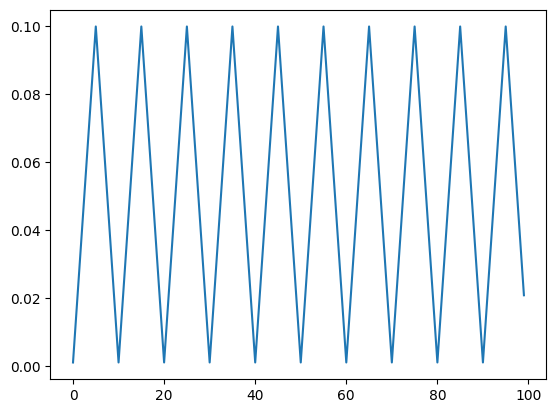

In [ ]:
model = torch.nn.Linear(2, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
scheduler = torch.optim.lr_scheduler.CyclicLR(optimizer, base_lr=0.001, max_lr=0.1,step_size_up=5,mode="triangular")
lrs = []


for i in range(100):
    optimizer.step()
    lrs.append(optimizer.param_groups[0]["lr"])
#     print("Factor = ",i," , Learning Rate = ",optimizer.param_groups[0]["lr"])
    scheduler.step()

plt.plot(lrs)

#### CyclicLR - triangular2

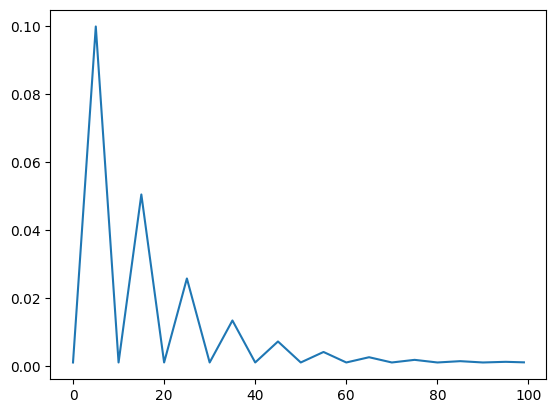

In [ ]:
model = torch.nn.Linear(2, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
scheduler = torch.optim.lr_scheduler.CyclicLR(optimizer, base_lr=0.001, max_lr=0.1,step_size_up=5,mode="triangular2")
lrs = []


for i in range(100):
    optimizer.step()
    lrs.append(optimizer.param_groups[0]["lr"])
#     print("Factor = ",i," , Learning Rate = ",optimizer.param_groups[0]["lr"])
    scheduler.step()

plt.plot(lrs)

#### CyclicLR - exp_range

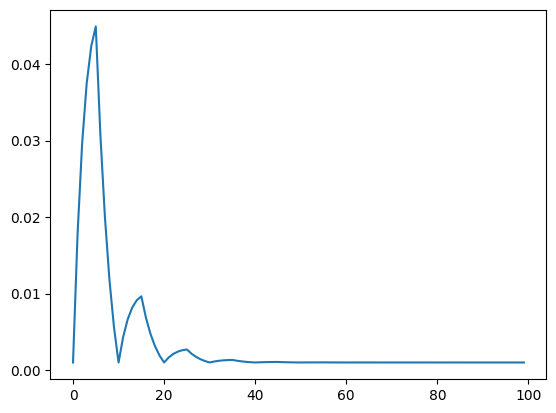

In [ ]:
model = torch.nn.Linear(2, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=100)
scheduler = torch.optim.lr_scheduler.CyclicLR(optimizer, base_lr=0.001, max_lr=0.1,step_size_up=5,mode="exp_range",gamma=0.85)
lrs = []

for i in range(100):
    optimizer.step()
    lrs.append(optimizer.param_groups[0]["lr"])
#     print("Factor = ",i," , Learning Rate = ",optimizer.param_groups[0]["lr"])
    scheduler.step()

plt.plot(lrs)

### [ReduceLROnPlateau](https://bo-10000.tistory.com/95)
- ReduceLROnPlateau는 더이상 학습이 진행되지 않을 때 learning rate를 감소시키는 scheduler이다.
- scheduler에 input으로 metric을 주면, 일정 epoch 동안 변화가 없을 때 learning rate를 감소시킨다

주요 Parameter은 다음과 같다.

- `mode`: [min, max] 중 하나. Input으로 주는 metric이 낮을수록 좋은지, 높을수록 좋은지를 의미한다. 'min' option을 주면, metric의 감소가 멈출 때마다 learning rate를 감소시킨다.
- `factor`: Learning rate를 감소시키는 비율. new_lr = lr * factor이 된다.
- `patience`: Metric이 얼마 동안 변화가 없을 때 learning rate를 감소시킬지 결정한다. 만약 patient=2라면, metric이 2 epoch 동안 변화가 없으면 learning rate를 감소시킨다.
- `threshold`: Metric이 '변화가 없다'라고 판단하는 threshold. Metric의 변화가 threshold 이하일 시 변화가 없다라고 판단한다.
- `cooldown`: 처음 몇 epoch 동안은 변화가 없어도 learning rate를 감소시키지 않는다. 몇 epoch만큼을 기다릴지를 지정한다.
- `eps`: Learning rate 감소의 최소치를 지정한다. new_lr과 old_lr의 차이가 eps 이하이면 더이상 learning rate를 감소시키지 않는다.

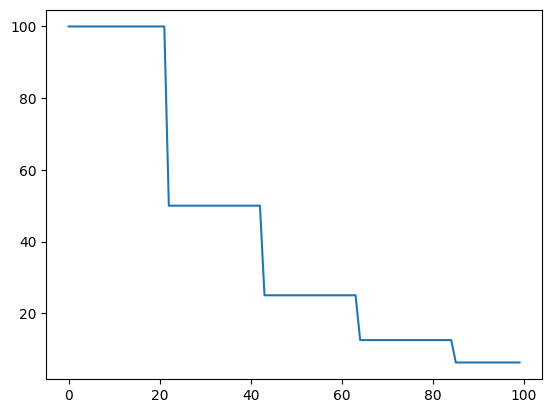

In [ ]:
model = torch.nn.Linear(2, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=100)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=20)
lrs = []


for i in range(100):
    optimizer.step()
    lrs.append(optimizer.param_groups[0]["lr"])
#     print("Factor = ",i," , Learning Rate = ",optimizer.param_groups[0]["lr"])
    scheduler.step(1)

plt.plot(lrs)

## [예제(StepLR)](https://ok-lab.tistory.com/257)

In [ ]:
import torch
import torch.nn as nn

from torch.optim.lr_scheduler import StepLR
import torch.optim as optim

from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.datasets as dsets

### Dataset & DataLoader

In [ ]:
train_dataset = dsets.MNIST(root='./sample_data',
                            train=True,
                            transform=transforms.ToTensor(),
                            download=True)

test_dataset = dsets.MNIST(root='./sample_data',
                           train=True,
                           transform=transforms.ToTensor(),
                           download=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 60.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.67MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.22MB/s]


In [ ]:
batch_size = 100
n_iters = 3000
num_epochs = n_iters / (len(train_dataset)/batch_size)
num_epochs = int(num_epochs)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

### Model

In [ ]:
class FFNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(FFNN, self).__init__()

        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim

        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()

        self.fc2 = nn.Linear(hidden_dim, output_dim)

        self._init_weight()

    def forward(self,images):
        out = self.fc1(images)
        out = self.relu(out)
        out = self.fc2(out)
        return out

    def _init_weight(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.kaiming_normal_(module.weight)
                nn.init.zeros_(module.bias)

### Training

In [ ]:
input_dim = 28 * 28
hidden_dim = 100
output_dim = 10
learning_rate = 1e-1

model = FFNN(input_dim, hidden_dim, output_dim)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9, nesterov=True)

# step_size를 지정하면 step 마다 learning rate를 gamma만큼 감소시킵니다.
# gamma = decaying factor
scheduler = StepLR(optimizer, step_size=1, gamma=0.1)

Epoch: 0, LR: [0.1]
Iteration: 500, Loss: 0.1654, Accuracy: 96.25%
Epoch: 1, LR: [0.010000000000000002]
Iteration: 1000, Loss: 0.0465, Accuracy: 97.67%
Epoch: 2, LR: [0.0010000000000000002]
Iteration: 1500, Loss: 0.1301, Accuracy: 97.78%
Epoch: 3, LR: [0.00010000000000000003]
Iteration: 2000, Loss: 0.0413, Accuracy: 97.82%
Epoch: 4, LR: [1.0000000000000004e-05]
Iteration: 2500, Loss: 0.1153, Accuracy: 97.82%
Iteration: 3000, Loss: 0.0848, Accuracy: 97.82%


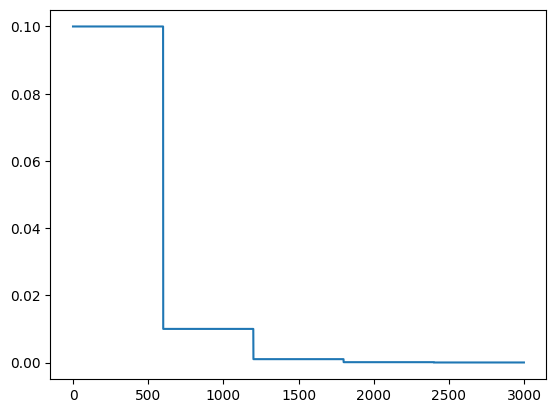

In [ ]:
iter = 0
lrs = []
for epoch in range(num_epochs):

    print(f'Epoch: {epoch}, LR: {scheduler.get_last_lr()}')

    model.train()
    for i, (images, labels) in enumerate(train_loader):
        images = images.view(-1, 28*28)

        optimizer.zero_grad()
        pred_y = model(images) # model.train()을 사용하지 않으면, images = imgaes.require_grad_()를 설정해주어야 합니다.
        loss = criterion(pred_y, labels)
        loss.backward()
        optimizer.step()
        lrs.append(optimizer.param_groups[0]["lr"])

        iter += 1

        if iter % 500 == 0 :
            correct = 0
            total = 0
            model.eval()
            for images, labels in test_loader:
                images = images.view(-1, 28*28)

                pred_y = model(images)
                pred_y = torch.argmax(pred_y.data, 1)

                total += labels.size(0)

                correct += (pred_y == labels).sum()

            accuracy = 100 * correct / total

            print(f'Iteration: {iter}, Loss: {loss.item():.4f}, Accuracy: {accuracy:.2f}%')
    # optimizer.step() 뒤에 적용해야 함!!
    # -> 즉, 역전파 프로세스가 완료된 후에 learning rate값을 변경해야 함
    # -> epoch(모든 데이터 학습)이 완료된 후에 적용
    scheduler.step()

plt.plot(lrs)

## 예제(CyclicLR - exp_range)

### Dataset

In [ ]:
import os
import pathlib
from PIL import Image
from pathlib import Path

from torch.utils.data import Dataset

In [ ]:
import requests
import zipfile
from pathlib import Path

# Setup path to data folder
data_path = Path("sample_data/")
image_path = data_path / "pizza_steak_sushi" # data/pizza_steak_sushi

# If the image folder doesn't exist, download it and prepare it...
if image_path.is_dir():
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)

    # Download pizza, steak, sushi data
    with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        print("Downloading pizza, steak, sushi data...")
        f.write(request.content)

    # Unzip pizza, steak, sushi data
    with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
        print("Unzipping pizza, steak, sushi data...")
        zip_ref.extractall(image_path)

Did not find sample_data/pizza_steak_sushi directory, creating one...
Unzipping pizza, steak, sushi data...


In [ ]:
# Setup train and testing paths
train_dir = image_path / "train"
test_dir = image_path / "test"

train_dir, test_dir

(PosixPath('sample_data/pizza_steak_sushi/train'),
 PosixPath('sample_data/pizza_steak_sushi/test'))

- 데이터 증강

In [ ]:
# 학습용 전체 데이터들....
train_dir_list = list(train_dir.glob("*/*.jpg"))
print(f'데이터 증강전: {len(train_dir_list)}')

for im_path in train_dir_list:
  _im = Image.open(im_path) # 원본 이미지 로드...
  _im_name = str(im_path).split(".")[0] # 원본 이미지 이름..

  # 상하반전... 저장
  _im.rotate(180).save(_im_name+"_rotate.jpg")
  # 좌우반전... 저장
  _im.transpose(Image.FLIP_LEFT_RIGHT).save(_im_name+"_transpose.jpg")

# 학습용 전체 데이터들....
train_dir_list = list(train_dir.glob("*/*.jpg"))
print(f'데이터 증강후: {len(train_dir_list)}')

데이터 증강전: 225
데이터 증강후: 675


In [ ]:
from typing import Tuple, Dict, List

# Make function to find classes in target directory
def find_classes(directory):
    # 1. Get the class names by scanning the target directory
    # classes -> ['pizza', 'steak', 'sushi']
    classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())


    # 2. Raise an error if class names not found
    if not classes:
        raise FileNotFoundError(f"Couldn't find any classes in {directory}.")

    # 3. Crearte a dictionary of index labels (computers prefer numerical rather than string labels)
    # class_to_idx -> classes to 숫자(인덱스)
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
    return classes, class_to_idx

In [ ]:
import pathlib

# Write a custom dataset class (inherits from torch.utils.data.Dataset)
from torch.utils.data import Dataset

# 1. Subclass torch.utils.data.Dataset
class ImageFolderCustom(Dataset):

    # 2. Initialize with a targ_dir and transform (optional) parameter
    def __init__(self, targ_dir: str, transform=None) -> None:

        # 3. Create class attributes
        # Get all image paths
        self.paths = list(pathlib.Path(targ_dir).glob("*/*.jpg")) # note: you'd have to update this if you've got .png's or .jpeg's
        # Setup transforms
        self.transform = transform
        # Create classes and class_to_idx attributes
        self.classes, self.class_to_idx = find_classes(targ_dir)

    # 4. Make function to load images
    def load_image(self, index: int) -> Image.Image:
        "Opens an image via a path and returns it."
        image_path = self.paths[index]
        return Image.open(image_path)

    # 5. Overwrite the __len__() method (optional but recommended for subclasses of torch.utils.data.Dataset)
    def __len__(self) -> int:
        "Returns the total number of samples."
        return len(self.paths)

    # 6. Overwrite the __getitem__() method (required for subclasses of torch.utils.data.Dataset)
    def __getitem__(self, index: int):
        "Returns one sample of data, data and label (X, y)."
        img = self.load_image(index)
        class_name  = self.paths[index].parent.name # expects path in data_folder/class_name/image.jpeg
        class_idx = self.class_to_idx[class_name]

        # Transform if necessary
        if self.transform:
            return self.transform(img), class_idx # return data, label (X, y)
        else:
            return img, class_idx # return data, label (X, y)


### transforms

In [ ]:
from torchvision import transforms

In [ ]:
import torchvision

efficientnet_weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
efficientnet_weights

EfficientNet_B0_Weights.IMAGENET1K_V1

In [ ]:
# Get the transforms used to create our pretrained weights
efficientnet_transforms = efficientnet_weights.transforms()
efficientnet_transforms

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

In [ ]:
# Turn image folders into Datasets
train_data_augmented = ImageFolderCustom(train_dir, transform=efficientnet_transforms)
test_data_simple = ImageFolderCustom(test_dir, transform=efficientnet_transforms)

train_data_augmented, test_data_simple

(<__main__.ImageFolderCustom at 0x7b1fa331da90>,
 <__main__.ImageFolderCustom at 0x7b1fa333cb90>)

### DataLoader

In [ ]:
import torch
from torch.utils.data import DataLoader

torch.manual_seed(42)
BATCH_SIZE = 32
train_dataloader = DataLoader(train_data_augmented,
                                        batch_size=BATCH_SIZE,
                                        shuffle=True)

test_dataloader = DataLoader(test_data_simple,
                                    batch_size=BATCH_SIZE,
                                    shuffle=False)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7b1fa333c910>,
 <torch.utils.data.dataloader.DataLoader at 0x7b1fa33690f0>)

### Model

In [ ]:
from torch import nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

class MyModel(nn.Module):
    # 사전학습 모델에 추가 layer 적용한 모델을 생성!!
    def __init__(self, target_size=3):
        super().__init__()
        self.pretrained_model = self.__get_efficientnet()

        self.classifier = nn.Sequential(
            nn.SiLU(),
            nn.Linear(in_features=1000, out_features=target_size)
        )

    def __get_efficientnet(self):
        weights = EfficientNet_B0_Weights.DEFAULT
        model = efficientnet_b0(weights=weights)

        for param in model.parameters():
            param.requires_grad = False

        return model

    def forward(self, features):
        out = self.pretrained_model(features)
        return self.classifier(out)


In [ ]:
multi_class_model = MyModel()

multi_class_model

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 100MB/s]


MyModel(
  (pretrained_model): EfficientNet(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
              (activation): SiLU(inplace=True)
              (sc

### Training

In [ ]:
def accuracy_fn(y_true, y_pred):
    # eq() -> equal를 뜻함 -> eq(y_true, y_pred) -> [true, false, flase, true ..]
    # eq(y_true, y_pred).sum() -> 정답 수
    # eq(y_true, y_pred).sum().item() -> python 형변환 함수
    correct = torch.eq(y_true, y_pred).sum().item() # torch.eq() calculates where two tensors are equal
    # 정확도 = ( 정답 수 / 전체 수 ) * 100
    acc = (correct / len(y_pred)) * 100

    return acc

In [ ]:
# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss() # this is also called "criterion"/"cost function" in some places
optimizer = torch.optim.SGD(params=multi_class_model.parameters(), lr=0.1)
scheduler = torch.optim.lr_scheduler.CyclicLR(optimizer, base_lr=0.001, max_lr=0.1,step_size_up=5,mode="exp_range",gamma=0.85)


In [ ]:
# Import tqdm for progress bar
from tqdm.auto import tqdm

# Create empty loss lists to track values
lrs = []
train_loss_values = []
test_loss_values = []
epoch_count = []
epochs = 20

for epoch in tqdm(range(epochs)):
    #################################################################
    ### Training Loop(dataloader) -> 모델 학습
    #################################################################
    train_loss = 0
    for batch, (X, y) in enumerate(train_dataloader):
        multi_class_model.train()
        y_pred = multi_class_model(X)
        loss = loss_fn(y_pred, y)
        train_loss += loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss /= len(train_dataloader)
    #################################################################
    ### Testing Loop -> 모델 평가
    #################################################################
    test_loss, test_acc = 0, 0
    multi_class_model.eval()
    with torch.inference_mode():
        for X, y in test_dataloader:
            test_pred = multi_class_model(X)
            test_loss += loss_fn(test_pred, y)
            pred_probab = nn.Softmax(dim=1)(test_pred)
            test_acc += accuracy_fn(y_true=y, y_pred=pred_probab.argmax(dim=1))

        test_loss /= len(test_dataloader)
        test_acc /= len(test_dataloader)

    #################################################################
    ### scheduler & Print
    #################################################################
    lrs.append(optimizer.param_groups[0]["lr"])
    scheduler.step()
    epoch_count.append(epoch)
    train_loss_values.append(train_loss.detach().numpy())
    test_loss_values.append(test_loss.detach().numpy())
    print(f"Epoch: {epoch} | Train loss: {train_loss:.5f} | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%\n")


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 0 | Train loss: 1.00921 | Test loss: 0.79822, Test acc: 67.99%

Epoch: 1 | Train loss: 0.43025 | Test loss: 0.37782, Test acc: 85.51%

Epoch: 2 | Train loss: 0.22955 | Test loss: 0.34157, Test acc: 85.51%

Epoch: 3 | Train loss: 0.17355 | Test loss: 0.39298, Test acc: 86.55%

Epoch: 4 | Train loss: 0.12466 | Test loss: 0.48103, Test acc: 80.40%

Epoch: 5 | Train loss: 0.10702 | Test loss: 0.50213, Test acc: 83.43%

Epoch: 6 | Train loss: 0.23523 | Test loss: 0.44724, Test acc: 85.51%

Epoch: 7 | Train loss: 0.15450 | Test loss: 0.37239, Test acc: 88.54%

Epoch: 8 | Train loss: 0.09092 | Test loss: 0.45640, Test acc: 81.44%

Epoch: 9 | Train loss: 0.11729 | Test loss: 0.42360, Test acc: 81.44%

Epoch: 10 | Train loss: 0.08322 | Test loss: 0.44423, Test acc: 81.44%

Epoch: 11 | Train loss: 0.05655 | Test loss: 0.39788, Test acc: 84.47%

Epoch: 12 | Train loss: 0.13108 | Test loss: 0.40996, Test acc: 84.47%

Epoch: 13 | Train loss: 0.14431 | Test loss: 0.38658, Test acc: 81.44%

Ep

### Plot

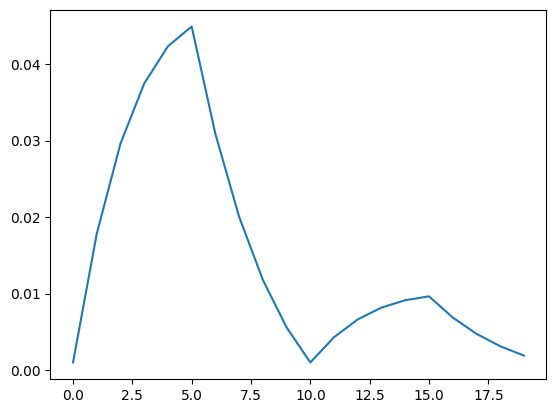

In [ ]:
import matplotlib.pyplot as plt

plt.plot(lrs)

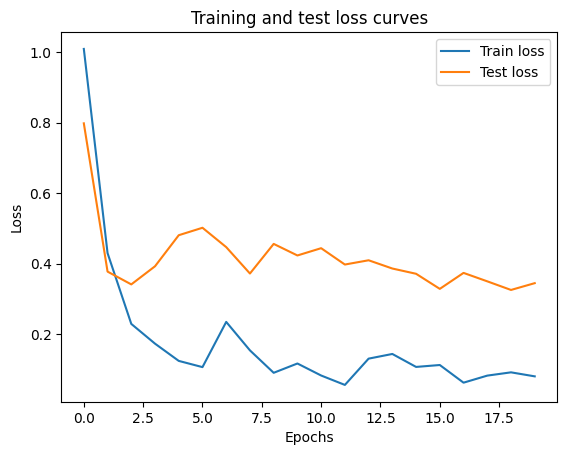

In [ ]:
# Plot the loss curves
plt.plot(epoch_count, train_loss_values, label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();